# Hedonic Pricing

We often try to predict the price of an asset from its observable characteristics. This is generally called **hedonic pricing**: How do the unit's characteristics determine its market price?

1. Clean the data `pierce_county_house_sales.csv` and perform some EDA and visualization to get to know the data set.
2. Transform your variables - particularly categorical ones - for use in your regression analysis.
3. Implement an 80/20 train-test split. Put the test data aside.
4. Build some simple linear models that include no transformations or interactions. Fit them, and determine their RMSE and $R^2$ on the both the training and test sets. Which of your models does the best?
5. Make partial correlation plots for each of the numeric variables in your model. Do you notice any significant non-linearities?
6. Include transformations and interactions of your variables, and build a more complex model that reflects your ideas about how the features of the asset determine its value. Determine its RMSE and $R^2$ on the training and test sets. How does the more complex model your build compare to the simpler ones?
7. Summarize your results from 1 to 6. Have you learned anything about overfitting and underfitting, or model selection?
8. Use the `sklearn.linear_model.Lasso` to regularize your model and select the most predictive features. Which does it select? What are the RMSE and $R^2$? We'll cover the Lasso later in detail in class.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Andrew Nguyen, Viet Huynh, Nathan Nguyen

**Date:** 11-8-26

In [10]:
# 1
import pandas as pd

df = pd.read_csv("data/pierce_county_house_sales.csv")
display(df.head())
print("rows and columns:", df.shape)
df.info()
display(df.isna().sum().sort_values(ascending=False))
print("duplicate rows:", df.duplicated().sum())
display(df.describe().T)

for col in ["waterfront_type", "view_quality", "hvac_description", "exterior", "interior", "roof_cover"]:
    print(f"\n{col}")
    print(df[col].value_counts(dropna=False))

# check unusual values
suspicious = df[(df["sale_price"] <= 0) | (df["house_square_feet"] <= 1) | (df["stories"] == 0) | (df["bedrooms"] == 0) | (df["bedrooms"] > 10) | (df["bathrooms"] == 0)]
display(suspicious)


FileNotFoundError: [Errno 2] No such file or directory: 'data/pierce_county_house_sales.csv'

In [11]:
# clean up
rows_before = len(df)
df = df.drop_duplicates().copy()
print("duplicates removed:", rows_before - len(df))

df["sale_date"] = pd.to_datetime(df["sale_date"])
cat_cols = df.select_dtypes(include=["object", "str"]).columns
df[cat_cols] = df[cat_cols].fillna("Not recorded")
df["hvac_description"] = df["hvac_description"].replace({"Floor Wall Furnace": "Floor/Wall Furnace"})

print("cleaned shape:", df.shape)
print("missing values left:", df.isna().sum().sum())


NameError: name 'df' is not defined

NameError: name 'df' is not defined

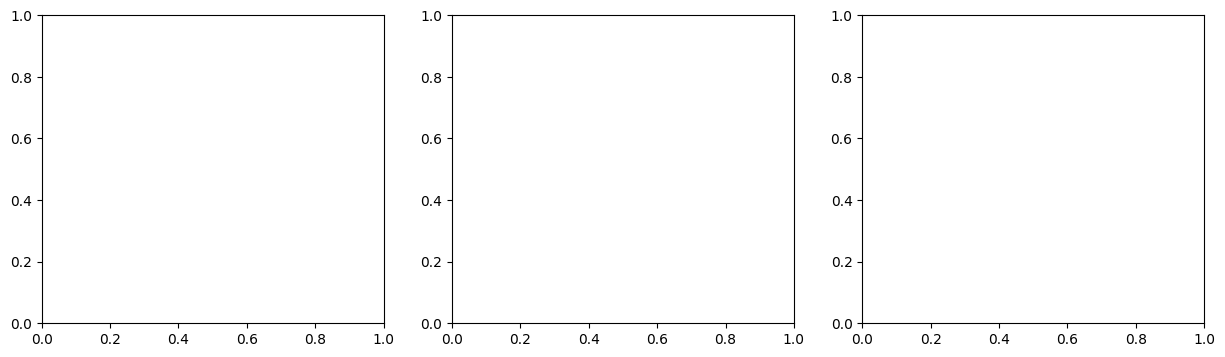

In [12]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].hist(df["sale_price"] / 1_000_000, bins=50, edgecolor="white")
axes[0].set(title="sale prices", xlabel="sale price ($ millions)", ylabel="number of sales")

axes[1].hist(df["house_square_feet"], bins=50, edgecolor="white")
axes[1].set(title="house sizes", xlabel="house area (square feet)", ylabel="number of sales")

axes[2].scatter(df["house_square_feet"], df["sale_price"] / 1_000_000, alpha=0.2, s=10)
axes[2].set(title="price vs house size", xlabel="house area (square feet)", ylabel="sale price ($ millions)")

plt.tight_layout()
plt.show()


The data started with 16,814 sales and 19 columns. I removed 46 exact duplicate rows, leaving 16,768. I'm treating those as repeated entries, but there isn't a property ID to confirm that. I also converted the sale dates and combined two heating labels that look like the same category.

Most of the waterfront and view values were blank. I used "Not recorded" for missing categories instead of dropping those rows or assuming a blank means the house has no waterfront or view.

There are some unusual values, like a house listed as 1 square foot, 25 bedrooms, and some houses with 0 stories, bedrooms, or bathrooms. I kept them for now since I don't know the correct values. I also kept zeros for garage, basement, and attic area since a house might just not have those features.

Sale prices are right-skewed, with a few expensive houses stretching out the distribution. House sizes also have a long right tail. Bigger houses generally sell for more, but prices still vary a lot for houses around the same size, so size alone probably won't explain everything.


In [13]:
# 2
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

X = df.drop(columns=["sale_price", "sale_date"])
y = df["sale_price"]
cat_cols = X.select_dtypes(include=["object", "str"]).columns.tolist()
num_cols = X.select_dtypes(include="number").columns.tolist()

preprocessor = ColumnTransformer([("categories", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), cat_cols)], remainder="passthrough")

print("categorical columns:", cat_cols)
print("numeric columns:", num_cols)
print("X shape:", X.shape)


NameError: name 'df' is not defined

I'm using sale price as the target and the house characteristics as predictors. I left out the sale date to keep these first models focused on the house itself.

Categorical columns will be one-hot encoded, so each category gets a 0/1 column instead of an arbitrary number. One category per feature is left out as the reference group. Numeric columns stay as they are for the simple models, with no interactions or nonlinear transformations yet.

This sets up the encoder, but doesn't fit it yet. I'll fit it using only the training data after the split in part 3. If a category only shows up in the test set, the encoder will let the model run, but it won't have learned a separate effect for that category.


In [14]:
# 3
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("training rows:", len(X_train))
print("test rows:", len(X_test))


NameError: name 'X' is not defined

I split the data into 80% training and 20% testing. The split shuffles the rows and keeps each house's features matched with its sale price. Random_state=42 makes the split repeatable so we can all use the same rows.

The models will learn from the training set. I'm keeping the test set aside until it's time to evaluate predictions, so we can see how the models do on sales they haven't trained on. The encoder will also be fitted on the training set when we build the models in part 4.


In [15]:
# 4
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import root_mean_squared_error, r2_score

models = {
    "size only": (["house_square_feet"], LinearRegression()),
    "numeric features": (num_cols, LinearRegression()),
    "all features": (X.columns.tolist(), make_pipeline(preprocessor, LinearRegression()))
}

results = []
for name, (cols, model) in models.items():
    model.fit(X_train[cols], y_train)
    train_pred = model.predict(X_train[cols])
    test_pred = model.predict(X_test[cols])
    results.append({
        "model": name,
        "train_rmse": root_mean_squared_error(y_train, train_pred),
        "test_rmse": root_mean_squared_error(y_test, test_pred),
        "train_r2": r2_score(y_train, train_pred),
        "test_r2": r2_score(y_test, test_pred)
    })

results = pd.DataFrame(results).set_index("model")
display(results.round(3))
print("lowest test rmse:", results["test_rmse"].idxmin())


NameError: name 'num_cols' is not defined

I compared three linear models: house size only, all numeric features, and all numeric plus categorical features. These use the same train/test split, with no nonlinear transformations or interactions. For the last model, the pipeline fits the encoder on the training data before fitting the regression, then uses that same encoding for predictions.

Lower RMSE and higher R² are better. RMSE is measured in dollars here and gives extra weight to bigger prediction errors. Test R² compares the predictions with just predicting the test set's mean price.

The model with all features did best on the test set. Its RMSE was about $154,378 and its R² was 0.517, compared with $170,422 and 0.411 for numeric features, and $189,647 and 0.270 for size alone. Adding the categorical features helped, so house size alone is missing useful information.

The best model's training R² was 0.554 compared with 0.517 on the test set, so there is a small drop on unseen data. It still leaves a lot of price variation unexplained. This gives us a starting point for checking nonlinear relationships and trying more complex models later. We shouldn't keep changing the models just to improve these test scores.


In [17]:
#5

import numpy as np

Z = models["all features"][1].named_steps["columntransformer"].transform(X_train)
names = preprocessor.get_feature_names_out()

fig, axes = plt.subplots(5, 2, figsize=(12, 18))

for col, ax in zip(num_cols, axes.flat):
    idx = list(names).index("remainder__" + col)
    controls = np.delete(Z, idx, axis=1)

    x_res = X_train[col] - LinearRegression().fit(
        controls, X_train[col]).predict(controls)
    y_res = y_train - LinearRegression().fit(
        controls, y_train).predict(controls)

    ax.scatter(x_res, y_res, alpha=0.2, s=5)
    ax.set_title(col)

plt.tight_layout()
plt.show()

NameError: name 'models' is not defined

Most relationships are close to linear. There is mild flattening for the largest houses, and year_built is slightly U-shaped. A few very expensive sales sit far above every trend line.

In [19]:
#6

X_train_new = X_train.copy()
X_test_new = X_test.copy()

for d in [X_train_new, X_test_new]:
    d["size_squared"] = (d["house_square_feet"] / 1000) ** 2
    d["year_squared"] = ((d["year_built"] - 1900) / 100) ** 2
    d["size_bathrooms"] = d["house_square_feet"] * d["bathrooms"]

complex_model = make_pipeline(preprocessor, LinearRegression())
complex_model.fit(X_train_new, y_train)

for X_data, y_data in [(X_train_new, y_train), (X_test_new, y_test)]:
    pred = complex_model.predict(X_data)
    print("RMSE:", root_mean_squared_error(y_data, pred))
    print("R2:", r2_score(y_data, pred))

NameError: name 'X_train' is not defined

I added squared terms and an interaction to capture more complex relationships between house features and sale price. I compared the training and test RMSE and R² with the simpler models to see whether these additional features improved predictions.

#7

The data showed that house size alone was not enough to accurately predict sale prices. Adding numeric and categorical features improved the model, with the all-features model performing best in Question 4. The complex model improved performance slightly more by capturing nonlinear relationships. However, the difference between training and test performance suggests some overfitting. I learned that adding features can improve predictions, but more complexity does not always lead to significantly better results.

In [21]:
#8

from sklearn.linear_model import LassoCV
from sklearn.preprocessing import StandardScaler

lasso_model = make_pipeline(
    preprocessor,
    StandardScaler(),
    LassoCV(cv=5, max_iter=30000)
)

lasso_model.fit(X_train_new, y_train)

for X_data, y_data in [(X_train_new, y_train),
                       (X_test_new, y_test)]:
    pred = lasso_model.predict(X_data)
    print("RMSE:", root_mean_squared_error(y_data, pred))
    print("R2:", r2_score(y_data, pred))

coef = lasso_model.named_steps["lassocv"].coef_
features = lasso_model.named_steps["columntransformer"].get_feature_names_out()

print("Selected features:")
print(features[coef != 0])

NameError: name 'preprocessor' is not defined

Lasso retained most of the features, including house size, year built, garage area, and interaction terms.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]